In [9]:
import pandas as pd
from sklearn.metrics import precision_score, accuracy_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

In [2]:
heart_df = pd.read_csv("heart.csv")
heart_df.head(1)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1


In [3]:
X = heart_df.drop("target", axis=1)
y = heart_df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
gnb_model = GaussianNB()
gnb_model.fit(X_train, y_train)

,priors,None
,var_smoothing,1e-09


In [5]:
y_pred = gnb_model.predict(X_test)

In [10]:
print("Accuracy:", accuracy_score(y_test, y_pred) * 100)
print("Precision:", precision_score(y_test, y_pred) * 100)
print("Recall:", recall_score(y_test, y_pred) * 100)
print("F1 Score:", f1_score(y_test, y_pred) * 100)

Accuracy: 81.9672131147541
Precision: 78.94736842105263
Recall: 90.9090909090909
F1 Score: 84.50704225352112


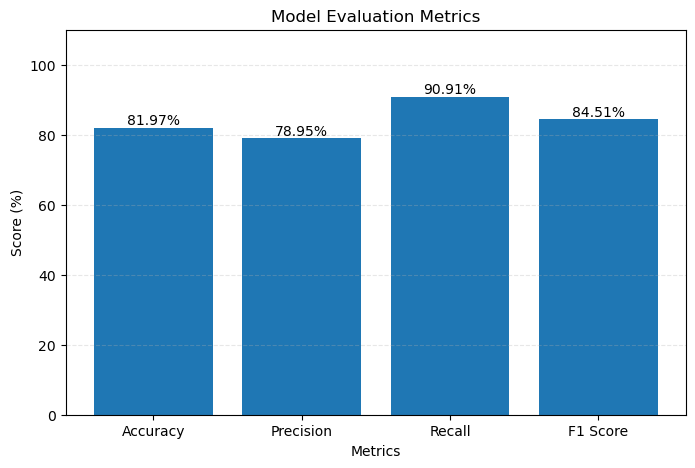

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred) * 100,
    "Precision": precision_score(y_test, y_pred) * 100,
    "Recall": recall_score(y_test, y_pred) * 100,
    "F1 Score": f1_score(y_test, y_pred) * 100
}
plt.figure(figsize=(8, 5))

bars = plt.bar(metrics.keys(), metrics.values())

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.title("Model Evaluation Metrics")
plt.xlabel("Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 110)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.show()